# CIFAR-10 embeddings: Simplex LDA (fixed identity covariance) vs Softmax

Train the convolutional encoder from `../lda/CIFAR10.ipynb` with two heads and
visualize its nine-dimensional embeddings using two-dimensional PCA.

- **Simplex LDA:** fixed regular-simplex class means, fixed covariance $\Sigma = I_9$,
  and trainable class priors. As in this folder's `CIFAR10.ipynb`, minimize the
  negative joint log score with `nn.NLLLoss()` (without applying `log_softmax`).
- **Softmax:** a trainable linear classifier optimized with cross-entropy.

Both models start with identical encoder weights and use the same training settings.
PCA is fitted separately for each model on the same unaugmented test images; the
panels have independent PCA axes and scales. Test labels only color the points and
measure accuracy. The figure is saved to `plots/cifar10_lda_vs_softmax_embeddings.png`.

Run all cells in order. Requires PyTorch, torchvision, and matplotlib; the first run
may download CIFAR-10. The default is 100 training epochs per model.

In [1]:
from pathlib import Path
import copy
import random
import sys

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Support kernels started in simplex-lda/ or its parent LDA/ directory.
project_dir = Path.cwd()
if not (project_dir / 'lda.py').is_file():
    project_dir = project_dir / 'simplex-lda'
if not (project_dir / 'lda.py').is_file():
    raise RuntimeError('Start the kernel in simplex-lda/ or its parent LDA/ directory.')
sys.path.insert(0, str(project_dir.resolve()))
from lda import SimplexLDAHead

SEED = 42
C, D = 10, 9
EPOCHS = 100
BATCH_SIZE = 256
NUM_WORKERS = 4  # Set to 0 if multiprocessing is unavailable.
LEARNING_RATE = 1e-3

def seed_everything(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
pin_memory = device.type == 'cuda'
plot_dir = project_dir / 'plots'
plot_dir.mkdir(parents=True, exist_ok=True)
print('device =', device)

device = cuda


## CIFAR-10 data
Use all 50,000 training images with the reference augmentations and all 10,000 test images with deterministic evaluation transforms.

In [2]:
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)
train_tfm = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
test_tfm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
train_ds = datasets.CIFAR10(
    root=str(project_dir / 'data'), train=True, transform=train_tfm, download=True
)
test_ds = datasets.CIFAR10(
    root=str(project_dir / 'data'), train=False, transform=test_tfm, download=True
)
test_ld = DataLoader(
    test_ds, batch_size=1024, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
print(f'Train: {len(train_ds):,}; test / PCA: {len(test_ds):,}')

Train: 50,000; test / PCA: 10,000


## Shared encoder and classification heads

In [3]:
class Encoder(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.proj = nn.Linear(256, dim)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.proj(x)


class DeepLDA(nn.Module):
    def __init__(self, C, D):
        super().__init__()
        self.encoder = Encoder(D)
        self.head = SimplexLDAHead(C, D, covariance_type="identity")

    def forward(self, x):
        return self.head(self.encoder(x))


class DeepSoftmax(nn.Module):
    def __init__(self, C, D):
        super().__init__()
        self.encoder = Encoder(D)
        self.head = nn.Linear(D, C)

    def forward(self, x):
        return self.head(self.encoder(x))


seed_everything(SEED)
lda_model = DeepLDA(C, D).to(device)
softmax_model = DeepSoftmax(C, D).to(device)
softmax_model.encoder.load_state_dict(copy.deepcopy(lda_model.encoder.state_dict()))

# Identity covariance has no trainable scale, diagonal, or Cholesky parameters.
assert set(dict(lda_model.head.named_parameters())) == {'prior_logits'}
assert torch.equal(lda_model.head.covariance, torch.eye(D, device=device))

## Train and evaluate

For identity covariance, the LDA score for class $c$ is
$\log \pi_c - \frac{1}{2}\lVert z - \mu_c\rVert^2$.
`nn.NLLLoss()` minimizes the negative true-class score, matching the Simplex LDA
maximum-likelihood objective in `CIFAR10.ipynb` (the constant Gaussian normalizer
has no effect on optimization). The Softmax baseline uses `nn.CrossEntropyLoss()`.
Training randomness and the shuffled loader are reset for each model.

In [4]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = total = 0
    for x, y in loader:
        logits = model(x.to(device, non_blocking=pin_memory))
        correct += (logits.argmax(1).cpu() == y).sum().item()
        total += y.size(0)
    return correct / total


def train_model(model, loss_fn, name):
    seed_everything(SEED)
    train_ld = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=pin_memory,
        generator=torch.Generator().manual_seed(SEED),
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {'loss': [], 'train_acc': [], 'test_acc': []}
    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum = correct = total = 0
        for x, y in train_ld:
            x = x.to(device, non_blocking=pin_memory)
            y = y.to(device, non_blocking=pin_memory)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = loss_fn(logits, y)
            loss.backward()
            optimizer.step()
            correct += (logits.detach().argmax(1) == y).sum().item()
            total += y.size(0)
            loss_sum += loss.item() * y.size(0)
        test_acc = evaluate(model, test_ld)
        history['loss'].append(loss_sum / total)
        history['train_acc'].append(correct / total)
        history['test_acc'].append(test_acc)
        print(f'[{name} {epoch:03d}] loss={loss_sum / total:.4f} '
              f'train acc={correct / total:.4f} | test acc={test_acc:.4f}')
    return history

In [5]:
lda_history = train_model(lda_model, nn.NLLLoss(), 'Simplex LDA, Sigma=I')
assert torch.equal(lda_model.head.covariance, torch.eye(D, device=device))

[Simplex LDA, Sigma=I 001] loss=8.0190 train acc=0.5227 | test acc=0.5620
[Simplex LDA, Sigma=I 002] loss=6.5041 train acc=0.6878 | test acc=0.7018
[Simplex LDA, Sigma=I 003] loss=5.8475 train acc=0.7558 | test acc=0.7241
[Simplex LDA, Sigma=I 004] loss=5.4627 train acc=0.7912 | test acc=0.7225
[Simplex LDA, Sigma=I 005] loss=5.1624 train acc=0.8180 | test acc=0.7779
[Simplex LDA, Sigma=I 006] loss=4.9542 train acc=0.8352 | test acc=0.7211
[Simplex LDA, Sigma=I 007] loss=4.7815 train acc=0.8474 | test acc=0.8034
[Simplex LDA, Sigma=I 008] loss=4.6387 train acc=0.8610 | test acc=0.8044
[Simplex LDA, Sigma=I 009] loss=4.5136 train acc=0.8706 | test acc=0.8331
[Simplex LDA, Sigma=I 010] loss=4.4047 train acc=0.8785 | test acc=0.8381
[Simplex LDA, Sigma=I 011] loss=4.3129 train acc=0.8856 | test acc=0.8578
[Simplex LDA, Sigma=I 012] loss=4.2259 train acc=0.8936 | test acc=0.8566
[Simplex LDA, Sigma=I 013] loss=4.1432 train acc=0.8989 | test acc=0.8561
[Simplex LDA, Sigma=I 014] loss=4.0864

In [6]:
softmax_history = train_model(softmax_model, nn.CrossEntropyLoss(), 'Softmax')

[Softmax 001] loss=1.3942 train acc=0.4932 | test acc=0.4740
[Softmax 002] loss=0.9314 train acc=0.6678 | test acc=0.6445
[Softmax 003] loss=0.7525 train acc=0.7351 | test acc=0.6202
[Softmax 004] loss=0.6387 train acc=0.7783 | test acc=0.7377
[Softmax 005] loss=0.5676 train acc=0.8040 | test acc=0.7784
[Softmax 006] loss=0.5144 train acc=0.8201 | test acc=0.7535
[Softmax 007] loss=0.4712 train acc=0.8361 | test acc=0.7954
[Softmax 008] loss=0.4322 train acc=0.8520 | test acc=0.7729
[Softmax 009] loss=0.3997 train acc=0.8625 | test acc=0.7497
[Softmax 010] loss=0.3800 train acc=0.8684 | test acc=0.8032
[Softmax 011] loss=0.3490 train acc=0.8770 | test acc=0.8298
[Softmax 012] loss=0.3339 train acc=0.8845 | test acc=0.8213
[Softmax 013] loss=0.3176 train acc=0.8904 | test acc=0.8067
[Softmax 014] loss=0.2952 train acc=0.8981 | test acc=0.8271
[Softmax 015] loss=0.2820 train acc=0.9029 | test acc=0.8511
[Softmax 016] loss=0.2678 train acc=0.9059 | test acc=0.8633
[Softmax 017] loss=0.254

## PCA of encoder embeddings

Collect both models' embeddings in a single pass over the test loader, ensuring
identical images and label order. Center each embedding matrix and compute exact
PCA using its SVD. No feature standardization or whitening is applied. The axis
labels show the fraction of total embedding variance explained by each component.

In [7]:
@torch.no_grad()
def collect_embeddings(lda_model, softmax_model, loader):
    lda_model.eval()
    softmax_model.eval()
    lda_embeddings, softmax_embeddings, labels = [], [], []
    for x, y in loader:
        x = x.to(device, non_blocking=pin_memory)
        lda_embeddings.append(lda_model.encoder(x).cpu())
        softmax_embeddings.append(softmax_model.encoder(x).cpu())
        labels.append(y.cpu())
    return (torch.cat(lda_embeddings), torch.cat(softmax_embeddings),
            torch.cat(labels))


def project_pca(z):
    z_centered = z.double() - z.double().mean(dim=0, keepdim=True)
    _, singular_values, vh = torch.linalg.svd(z_centered, full_matrices=False)
    projected = z_centered @ vh[:2].T
    variances = singular_values.square()
    explained = variances[:2] / variances.sum().clamp_min(torch.finfo(z_centered.dtype).eps)
    return projected.numpy(), explained.numpy()


lda_z, softmax_z, labels = collect_embeddings(lda_model, softmax_model, test_ld)
lda_z2, lda_explained = project_pca(lda_z)
softmax_z2, softmax_explained = project_pca(softmax_z)
labels = labels.numpy()
print(f'PCA uses {len(labels):,} matching test images per model.')

PCA uses 10,000 matching test images per model.


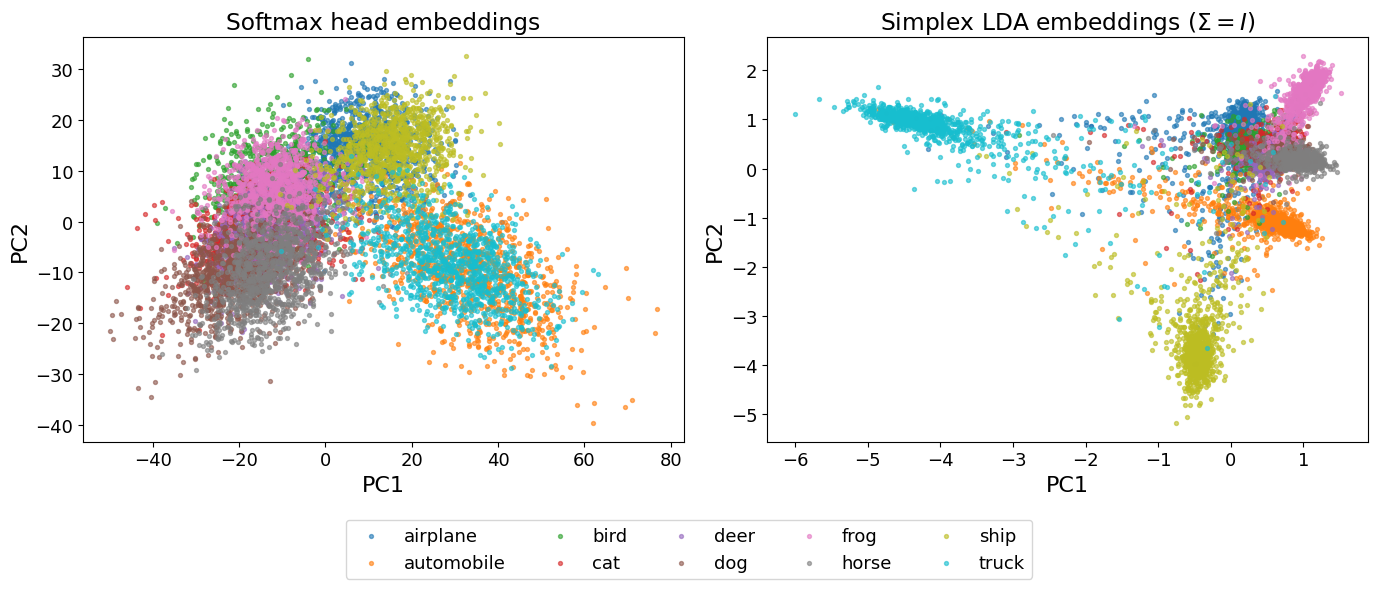

Saved: /home/zhenisbek/LDA/simplex-lda/plots/cifar10_lda_vs_softmax_embeddings.png


In [10]:
plt.rcParams.update({
    'font.size': 14, 'axes.labelsize': 16, 'legend.fontsize': 13,
    'xtick.labelsize': 13, 'ytick.labelsize': 13,
})
palette = plt.cm.tab10.colors
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plots = [
    (axes[0], softmax_z2, softmax_explained, 'Softmax head embeddings'),
    (axes[1], lda_z2, lda_explained, r'Simplex LDA embeddings ($\Sigma = I$)'),
]
for ax, z2, explained, title in plots:
    for c, class_name in enumerate(test_ds.classes):
        mask = labels == c
        ax.scatter(z2[mask, 0], z2[mask, 1], s=8, alpha=0.6,
                   color=palette[c], label=class_name)
    ax.set_xlabel(f'PC1')
    ax.set_ylabel(f'PC2')
    ax.set_title(title)

handles, class_names = axes[0].get_legend_handles_labels()
fig.legend(handles, class_names, loc='lower center', ncol=5,
           bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.12, 1, 1))
output_path = plot_dir / 'cifar10_lda_vs_softmax_embeddings.png'
fig.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()
print('Saved:', output_path.resolve())